# Emotion classifier, day 2: fine-tuning DistilBERT

Day 1 gave a baseline (TF-IDF + logistic regression): **accuracy 0.861, macro-F1 0.792** on the test set.

Today a small neural network that already understands English (DistilBERT) is trained a little further
on the emotion data. This is called **fine-tuning**.

**Before you run anything:** in the menu choose **Runtime → Change runtime type → T4 GPU → Save**.
Then run the cells from top to bottom with `Shift+Enter`.

## 1. Setup

A GPU (graphics card) does the many small calculations of a neural network in parallel.
Training takes a few minutes on a GPU and more than an hour without one, so the first cell checks that it is there.

In [1]:
import os

# Plain text output instead of animated progress bars, so GitHub can display this notebook later.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU! Choose Runtime -> Change runtime type -> T4 GPU, then run this cell again.")

GPU available: True
GPU: Tesla T4


In [2]:
# The exclamation mark runs a terminal command inside the notebook.
!pip install -q datasets

## 2. Load the data

The same dataset as on day 1: 16,000 training sentences, 2,000 for validation, 2,000 for the final test.

In [3]:
from datasets import disable_progress_bars, load_dataset

disable_progress_bars()

dataset = load_dataset("dair-ai/emotion", "split")
label_names = dataset["train"].features["label"].names

print(dataset)
print(label_names)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


## 3. Tokenize: turn text into numbers

On day 1, TF-IDF turned a sentence into word counts and threw the word order away.
DistilBERT needs the words **in order**, so the text is cut into small pieces called **tokens**,
and each token is replaced by its number in the model's dictionary (about 30,000 entries).

- A common word is one token. A rare word is split into several pieces (the `##` marks a continuation).
- `[CLS]` is added at the start and `[SEP]` at the end. The model uses the `[CLS]` position to
  collect its summary of the whole sentence.

In [4]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"   # "uncased" = everything is lowercased first
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = "i don t feel particularly agitated"
encoded = tokenizer(example)

print("text:   ", example)
print("tokens: ", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("numbers:", encoded["input_ids"])

text:    i don t feel particularly agitated
tokens:  ['[CLS]', 'i', 'don', 't', 'feel', 'particularly', 'agitated', '[SEP]']
numbers: [101, 1045, 2123, 1056, 2514, 3391, 21568, 102]


In [5]:
def tokenize(batch):
    # truncation=True cuts sentences longer than max_length tokens (very rare in this dataset).
    return tokenizer(batch["text"], truncation=True, max_length=128)


# map() runs the function over every row and adds the result as new columns.
tokenized = dataset.map(tokenize, batched=True)

print(tokenized["train"].column_names)

['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


## 4. Load the pretrained model

DistilBERT was trained on a huge amount of English text to guess hidden words.
From that it learned grammar and meaning, but nothing about our six emotions.

`AutoModelForSequenceClassification` takes that model and puts a small, new, untrained layer on top:
6 outputs, one per emotion. **The warning that some weights are "newly initialized" is expected**:
it is exactly that new layer, and training it is today's job.

In [6]:
from transformers import AutoModelForSequenceClassification

id2label = dict(enumerate(label_names))                      # {0: "sadness", 1: "joy", ...}
label2id = {name: number for number, name in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
)

print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


66,958,086 parameters


## 5. How the model is scored

The model returns 6 raw scores per sentence, called **logits**. The highest one is the prediction.
This function is called after every round of training and reports the same two numbers as on day 1.

In [7]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score


def compute_metrics(eval_prediction):
    logits = eval_prediction.predictions
    labels = eval_prediction.label_ids
    predictions = np.argmax(logits, axis=-1)     # position of the highest score in each row
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
    }

## 6. Train

The settings, in plain words:

| Setting | Meaning |
|---|---|
| `num_train_epochs=3` | An **epoch** is one full pass over all 16,000 training sentences. Three passes. |
| `per_device_train_batch_size=32` | The model looks at 32 sentences, then adjusts its weights once. 16,000 / 32 = 500 steps per epoch. |
| `learning_rate=2e-5` | How big each adjustment is (0.00002). Small on purpose: the model already knows English, we only nudge it. |
| `weight_decay=0.01` | Gently keeps weights small, which reduces memorising. |
| `eval_strategy="epoch"` | Check on the validation set after every epoch. |
| `load_best_model_at_end=True` | At the end, keep the version with the best validation macro-F1. |
| `fp16=True` | Use lighter numbers on the GPU, which makes training faster. |

**Expected:** a progress bar with 1500 steps and a table that gets one new row per epoch.
It takes a few minutes on the T4 GPU.

In [8]:
from transformers import DataCollatorWithPadding, Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    # Sentences have different lengths. The collator fills the shorter ones in each
    # batch with empty "padding" tokens so they form a neat rectangle of numbers.
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.260736,0.201908,0.926000,0.899338
2,0.139461,0.157906,0.936500,0.909431
3,0.101796,0.148584,0.936500,0.911211


TrainOutput(global_step=1500, training_loss=0.3021693499883016, metrics={'train_runtime': 124.358, 'train_samples_per_second': 385.982, 'train_steps_per_second': 12.062, 'total_flos': 647803507542912.0, 'train_loss': 0.3021693499883016, 'epoch': 3.0})

## 7. The real exam: the test set

Until now only the validation set was used. The test set is opened here, once.

In [9]:
from sklearn.metrics import classification_report

output = trainer.predict(tokenized["test"])
test_predictions = np.argmax(output.predictions, axis=-1)
test_labels = output.label_ids

test_accuracy = accuracy_score(test_labels, test_predictions)
test_macro_f1 = f1_score(test_labels, test_predictions, average="macro")

print(classification_report(test_labels, test_predictions, target_names=label_names, digits=3))

              precision    recall  f1-score   support

     sadness      0.959     0.960     0.960       581
         joy      0.952     0.941     0.946       695
        love      0.818     0.849     0.833       159
       anger      0.924     0.924     0.924       275
        fear      0.867     0.929     0.897       224
    surprise      0.882     0.682     0.769        66

    accuracy                          0.927      2000
   macro avg      0.900     0.881     0.888      2000
weighted avg      0.928     0.927     0.927      2000



In [10]:
# The baseline numbers come from baseline.py on day 1.
BASELINE_ACCURACY = 0.861
BASELINE_MACRO_F1 = 0.792

print(f"{'model':<34}{'accuracy':>10}{'macro-F1':>10}")
print(f"{'TF-IDF + logistic regression':<34}{BASELINE_ACCURACY:>10.3f}{BASELINE_MACRO_F1:>10.3f}")
print(f"{'DistilBERT (fine-tuned)':<34}{test_accuracy:>10.3f}{test_macro_f1:>10.3f}")
print(f"{'difference':<34}{test_accuracy - BASELINE_ACCURACY:>+10.3f}{test_macro_f1 - BASELINE_MACRO_F1:>+10.3f}")

model                               accuracy  macro-F1
TF-IDF + logistic regression           0.861     0.792
DistilBERT (fine-tuned)                0.927     0.888
difference                            +0.066    +0.096


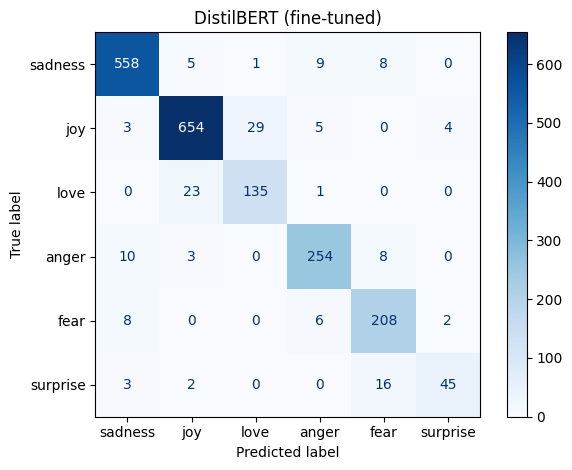

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    test_labels, test_predictions, display_labels=label_names, cmap="Blues"
)
plt.title("DistilBERT (fine-tuned)")
plt.tight_layout()
plt.savefig("distilbert_confusion_matrix.png", dpi=150)
plt.show()

## 8. Try the sentences the baseline got wrong

These four come from the "wrong predictions" list of day 1. The true emotion is in brackets.
Add your own sentences to the list as well.

In [12]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer,
    device=trainer.model.device,
)

sentences = [
    ("fear", "i don t feel particularly agitated"),
    ("joy", "i just feel extremely comfortable with the group of people that i dont even need to hide myself"),
    ("fear", "i pay attention it deepens into a feeling of being invaded and helpless"),
    ("sadness", "im not sure the feeling of loss will ever go away but it may dull to a sweet feeling of nostalgia at what i shared in this life with my dad and the luck i had to have a dad for years"),
]

for true_label, text in sentences:
    result = classifier(text)[0]
    mark = "correct" if result["label"] == true_label else "wrong"
    print(f"true: {true_label:<8} predicted: {result['label']:<8} ({result['score']:.0%})  {mark}")
    print("   ", text[:90])

true: fear     predicted: anger    (67%)  wrong
    i don t feel particularly agitated
true: joy      predicted: joy      (100%)  correct
    i just feel extremely comfortable with the group of people that i dont even need to hide m
true: fear     predicted: fear     (96%)  correct
    i pay attention it deepens into a feeling of being invaded and helpless
true: sadness  predicted: sadness  (96%)  correct
    im not sure the feeling of loss will ever go away but it may dull to a sweet feeling of no


## 9. Save the model

Colab deletes everything when the session ends, so the trained model has to be stored somewhere.
It goes to your Hugging Face account, where the demo on day 3 will load it from.

You need a free account on huggingface.co and an access token of type **Write**
(Settings → Access Tokens → Create new token). Paste the token when the cell asks for it.
The input stays hidden and is not saved in the notebook.

In [13]:
from getpass import getpass

from huggingface_hub import login

login(token=getpass("Paste your Hugging Face token and press Enter: "))

REPO_NAME = "emotion-distilbert"
trainer.model.push_to_hub(REPO_NAME)
tokenizer.push_to_hub(REPO_NAME)
print("Uploaded. Find it on your Hugging Face profile under Models.")

Paste your Hugging Face token and press Enter: ··········
Uploaded. Find it on your Hugging Face profile under Models.


In [14]:
# Download the confusion matrix picture to your PC, for the GitHub repo.
from google.colab import files

files.download("distilbert_confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>